# 01 Data Exploration

Extracted from `FP_NewsBot2_ksm_GroupName_ITAI2373.ipynb` (original outputs kept). Midterm part of the project notebook: data loading, preprocessing, TF-IDF, POS, syntax, sentiment (cells 0-51). Classification/NER/integration of the midterm remain in the full notebook.

Upload `BBC News Train.csv` (in `data/raw/`) to Colab before running.

# 🤖 NewsBot Intelligence System
## ITAI 2373 - Mid-Term Group Project Template

**Team Members:** khalida Bestani, Sadea Saeed, Marisabel Morales
**Date:** [Add date]
**GitHub Repository:** [Add your repo URL here]

---

## 🎯 Project Overview

Welcome to your NewsBot Intelligence System! This notebook will guide you through building a comprehensive NLP system that:

- 📰 **Processes** news articles with advanced text cleaning
- 🏷️ **Classifies** articles into categories (Politics, Sports, Technology, Business, Entertainment, Health)
- 🔍 **Extracts** named entities (people, organizations, locations, dates, money)
- 😊 **Analyzes** sentiment and emotional tone
- 📊 **Generates** insights for business intelligence

### 📚 Module Integration Checklist
- [ ] **Module 1:** NLP applications and real-world context
- [ ] **Module 2:** Text preprocessing pipeline
- [ ] **Module 3:** TF-IDF feature extraction
- [ ] **Module 4:** POS tagging analysis
- [ ] **Module 5:** Syntax parsing and semantic analysis
- [ ] **Module 6:** Sentiment and emotion analysis
- [ ] **Module 7:** Text classification system
- [ ] **Module 8:** Named Entity Recognition

---

## 📦 Setup and Installation

Let's start by installing and importing all the libraries we'll need for our NewsBot system.

In [ ]:

!pip install kaggle

from google.colab import files

print("Please upload your kaggle.json file:")
uploaded = files.upload()


Please upload your kaggle.json file:


Saving kaggle.json to kaggle.json


In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

print("Kaggle API setup complete!")


Kaggle API setup complete!


In [ ]:
!kaggle competitions download -c learn-ai-bbc


100% 1.85M/1.85M [00:00<00:00, 69.8MB/s]



In [ ]:
!unzip -o learn-ai-bbc.zip
!ls -la

import pandas as pd
import os

print("Available files:")
for file in os.listdir('.'):
    if file.endswith('.csv'):
        print(f" - {file}")


Archive:  learn-ai-bbc.zip
  inflating: BBC News Sample Solution.csv  
  inflating: BBC News Test.csv       
  inflating: BBC News Train.csv      
total 6876
drwxr-xr-x 1 root root    4096 Oct 11 00:23  .
drwxr-xr-x 1 root root    4096 Oct 11 00:04  ..
-rw-r--r-- 1 root root   10369 Dec  2  2019 'BBC News Sample Solution.csv'
-rw-r--r-- 1 root root 1712432 Dec  2  2019 'BBC News Test.csv'
-rw-r--r-- 1 root root 3351206 Dec  2  2019 'BBC News Train.csv'
drwxr-xr-x 4 root root    4096 Oct  2 13:50  .config
-rw-r--r-- 1 root root      65 Oct 11 00:23  kaggle.json
-rw-r--r-- 1 root root 1936538 Dec  2  2019  learn-ai-bbc.zip
drwxr-xr-x 1 root root    4096 Oct  2 13:50  sample_data
Available files:
 - BBC News Test.csv
 - BBC News Train.csv
 - BBC News Sample Solution.csv


In [ ]:
import pandas as pd
import os

# Load the BBC News training dataset
df = pd.read_csv('BBC News Train.csv')

# Display dataset information
print(f"Dataset shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
print(f"Categories: {df['Category'].unique()}")


Dataset shape: (1490, 3)
Columns: ['ArticleId', 'Text', 'Category']
Categories: ['business' 'tech' 'politics' 'sport' 'entertainment']


In [ ]:
# Check for missing values
print(df.isnull().sum())

# Count articles in each category
print("\nArticles per category:")
print(df['Category'].value_counts())

# Display one example article
print("\nExample article:")
print(df['Text'].iloc[0][:500])


ArticleId    0
Text         0
Category     0
dtype: int64

Articles per category:
Category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64

Example article:
worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.  cynthia cooper  worldcom s ex-head of internal accounting  alerted directors to irregular accounting practices at the us telecoms giant in 2002. her warnings led to the collapse of the firm following the discovery of an $11bn (£5.7bn) accounting fraud. mr ebbers has pleaded not guilty to charges of fraud and conspi


In [ ]:
# Data preparation template
import pandas as pd
import numpy as np

# 1. Examine your dataset
print("Dataset Info:")
print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
print("\nFirst few rows:")
print(df.head())

# 2. Identify text and category columns
text_column = 'Text'
category_column = 'Category'

# 3. Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# 4. Remove rows with missing text or categories
df_clean = df.dropna(
    subset=[text_column, category_column]
)

# 5. Check category distribution
print("\nCategory distribution:")
print(df_clean[category_column].value_counts())

# 6. Sample if dataset is too large
if len(df_clean) > 2000:
    df_final = df_clean.sample(
        n=2000, random_state=42
    )
    print(f"\nSampled dataset to {len(df_final)} rows")
else:
    df_final = df_clean

# 7. Rename columns for consistency
df_final = df_final.rename(columns={
    'ArticleId': 'article_id',
    text_column: 'content',
    category_column: 'category'
})

# 8. Save prepared dataset
df_final.to_csv('newsbot_dataset.csv', index=False)

print("\nDataset prepared and saved as 'newsbot_dataset.csv'")


Dataset Info:
Shape: (1490, 3)
Columns: ['ArticleId', 'Text', 'Category']

First few rows:
   ArticleId                                               Text  Category
0       1833  worldcom ex-boss launches defence lawyers defe...  business
1        154  german business confidence slides german busin...  business
2       1101  bbc poll indicates economic gloom citizens in ...  business
3       1976  lifestyle  governs mobile choice  faster  bett...      tech
4        917  enron bosses in $168m payout eighteen former e...  business

Missing values:
ArticleId    0
Text         0
Category     0
dtype: int64

Category distribution:
Category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64

Dataset prepared and saved as 'newsbot_dataset.csv'


In [ ]:
# Install required packages (run this cell first!)
!pip install spacy scikit-learn nltk pandas matplotlib seaborn wordcloud plotly
!python -m spacy download en_core_web_sm

# Download NLTK data
import nltk
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('vader_lexicon')
nltk.download('averaged_perceptron_tagger')

print("✅ All packages installed successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 92.1 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


✅ All packages installed successfully!


[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.


In [ ]:
# Import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import plotly.express as px
import plotly.graph_objects as go
from collections import Counter, defaultdict
import re
import warnings
warnings.filterwarnings('ignore')

# NLP Libraries
import spacy
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tag import pos_tag

# Scikit-learn for machine learning
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.pipeline import Pipeline

# Load spaCy model
nlp = spacy.load('en_core_web_sm')

# Set up plotting style
plt.style.use('default')
sns.set_palette("husl")

print("📚 All libraries imported successfully!")
print(f"🔧 spaCy model loaded: {nlp.meta['name']} v{nlp.meta['version']}")

📚 All libraries imported successfully!
🔧 spaCy model loaded: core_web_sm v3.8.0


**Setup & Data**
In this section, I learned how to connect my notebook to Kaggle and load the BBC News dataset. I checked the number of articles, the five categories, and missing values. These checks helped me confirm that my dataset was ready for the next steps of the NLP project.

## 📊 Data Loading and Exploration

### 🎯 Module 1: Understanding Our NLP Application

Before we dive into the technical implementation, let's understand the real-world context of our NewsBot Intelligence System. This system addresses several business needs:

1. **Media Monitoring:** Automatically categorize and track news coverage
2. **Business Intelligence:** Extract key entities and sentiment trends
3. **Content Management:** Organize large volumes of news content
4. **Market Research:** Understand public sentiment about topics and entities

**💡 Discussion Question:** What other real-world applications can you think of for this type of system? Consider different industries and use cases.

I added a new code cell to load the prepared BBC News dataset instead of using the instructor's sample dataset. The sample dataset contained only 10 articles, which did not meet the project requirement of at least 500 articles. I used the BBC dataset with 1,490 articles across five categories and no missing values to make sure my project followed the dataset requirements.

In [ ]:
# Load your dataset
# 💡 TIP: If using the provided dataset, upload it to Colab first
# 💡 TIP: You can also use sample datasets like BBC News or 20 Newsgroups

# Option 1: Load provided dataset
# df = pd.read_csv('news_dataset.csv')

# Option 2: Load BBC News dataset (if using alternative)
# You can download this from: https://www.kaggle.com/c/learn-ai-bbc/data

# Option 3: Create sample data for testing (remove this when you have real data)
sample_data = {
    'article_id': range(1, 11),
    'title': [
        'Apple Inc. Reports Record Quarterly Earnings',
        'Manchester United Defeats Chelsea 3-1',
        'New AI Technology Revolutionizes Healthcare',
        'President Biden Announces Climate Initiative',
        'Netflix Releases New Original Series',
        'Tesla Stock Rises After Production Update',
        'Olympic Games Begin in Paris',
        'Google Launches New Search Algorithm',
        'Congress Passes Infrastructure Bill',
        'Disney+ Subscriber Numbers Grow'
    ],
    'content': [
        'Apple Inc. announced record quarterly earnings today, with CEO Tim Cook highlighting strong iPhone sales and services revenue growth.',
        'Manchester United secured a convincing 3-1 victory over Chelsea at Old Trafford, with goals from Marcus Rashford and Bruno Fernandes.',
        'A breakthrough AI system developed by researchers at Stanford University shows promise for early disease detection in medical imaging.',
        'President Joe Biden unveiled a comprehensive climate change initiative aimed at reducing carbon emissions by 50% over the next decade.',
        'Netflix premiered its latest original series to critical acclaim, featuring an ensemble cast and innovative storytelling techniques.',
        'Tesla shares jumped 8% in after-hours trading following the company\'s announcement of increased production capacity at its Texas facility.',
        'The 2024 Olympic Games officially began in Paris with a spectacular opening ceremony attended by world leaders and celebrities.',
        'Google introduced a new search algorithm that promises more accurate and contextually relevant results for users worldwide.',
        'The U.S. Congress passed a bipartisan infrastructure bill allocating $1.2 trillion for roads, bridges, and broadband expansion.',
        'Disney+ reported strong subscriber growth in Q3, reaching 150 million subscribers globally across all markets.'
    ],
    'category': ['Business', 'Sports', 'Technology', 'Politics', 'Entertainment',
                'Business', 'Sports', 'Technology', 'Politics', 'Entertainment'],
    'date': ['2024-01-15'] * 10,
    'source': ['TechNews', 'SportsTimes', 'TechDaily', 'PoliticsToday', 'EntertainmentWeekly',
              'BusinessWire', 'SportsCentral', 'TechReview', 'NewsNow', 'ShowBiz']
}

df = pd.DataFrame(sample_data)

print(f"📊 Dataset loaded successfully!")
print(f"📈 Shape: {df.shape}")
print(f"📋 Columns: {list(df.columns)}")

# Display first few rows
df.head()

📊 Dataset loaded successfully!
📈 Shape: (10, 6)
📋 Columns: ['article_id', 'title', 'content', 'category', 'date', 'source']


,article_id,title,content,category,date,source
0,1,Apple Inc. Reports Record Quarterly Earnings,Apple Inc. announced record quarterly earnings...,Business,2024-01-15,TechNews
1,2,Manchester United Defeats Chelsea 3-1,Manchester United secured a convincing 3-1 vic...,Sports,2024-01-15,SportsTimes
2,3,New AI Technology Revolutionizes Healthcare,A breakthrough AI system developed by research...,Technology,2024-01-15,TechDaily
3,4,President Biden Announces Climate Initiative,President Joe Biden unveiled a comprehensive c...,Politics,2024-01-15,PoliticsToday
4,5,Netflix Releases New Original Series,Netflix premiered its latest original series t...,Entertainment,2024-01-15,EntertainmentWeekly


In [ ]:
df = pd.read_csv('newsbot_dataset.csv')

print("Dataset restored!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())


Dataset restored!
Shape: (1490, 3)
Columns: ['article_id', 'content', 'category']


** Basic Dataset Exploration**
This section explores the news dataset by checking its size, columns, and categories. This helps me understand the data before starting the NLP analysis.

📊 DATASET OVERVIEW
Total articles: 1490
Unique categories: 5
Categories: ['business', 'tech', 'politics', 'sport', 'entertainment']

📈 CATEGORY DISTRIBUTION
category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64


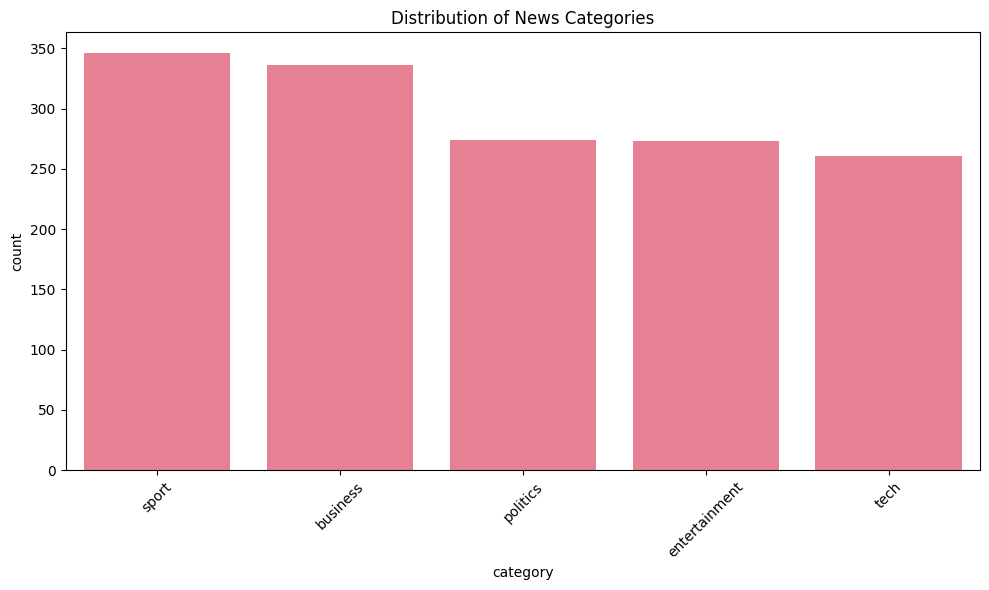

In [ ]:
# Basic dataset exploration
print("📊 DATASET OVERVIEW")
print("=" * 50)
print(f"Total articles: {len(df)}")
print(f"Unique categories: {df['category'].nunique()}")
print(f"Categories: {df['category'].unique().tolist()}")

print("\n📈 CATEGORY DISTRIBUTION")
print("=" * 50)
category_counts = df['category'].value_counts()
print(category_counts)

# Visualize category distribution
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='category', order=category_counts.index)
plt.title('Distribution of News Categories')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 💡 STUDENT TASK: Add your own exploratory analysis here
# - Check for missing values
# - Analyze text length distribution
# - Look for any data quality issues

### Dataset Visualization

These charts help me understand the distribution of news articles across categories and identify patterns in the dataset before preprocessing.

In [ ]:
# Check for missing values
print("\nMissing values:")
print(df[['content', 'category']].isnull().sum())

# Analyze text length distribution
df['text_length'] = df['content'].str.len()
print("\nText length statistics:")
print(df['text_length'].describe())



Missing values:
content     0
category    0
dtype: int64

Text length statistics:
count     1490.000000
mean      2233.461745
std       1205.153358
min        501.000000
25%       1453.000000
50%       1961.000000
75%       2751.250000
max      18387.000000
Name: text_length, dtype: float64


### Text Statistics Analysis

In this section, I examine the length of the news articles. This helps me understand how much text the dataset contains and identify differences in article length before preprocessing.

**Why I Added This Code**

I added this code to check the quality of my BBC News dataset before starting the NLP analysis. First, I checked for missing values in the content and category columns to make sure the articles have text and category labels. Then, I analyzed the text length to understand how long the articles are and verify that the dataset contains substantial text rather than only headlines. These checks help me make sure the dataset is suitable for the next steps of my project.

## 🧹 Text Preprocessing Pipeline

### 🎯 Module 2: Advanced Text Preprocessing

Now we'll implement a comprehensive text preprocessing pipeline that cleans and normalizes our news articles. This is crucial for all downstream NLP tasks.

**Key Preprocessing Steps:**
1. **Text Cleaning:** Remove HTML, URLs, special characters
2. **Tokenization:** Split text into individual words
3. **Normalization:** Convert to lowercase, handle contractions
4. **Stop Word Removal:** Remove common words that don't carry meaning
5. **Lemmatization:** Reduce words to their base form

**💡 Think About:** Why is preprocessing so important? What happens if we skip these steps?

add import nltk

nltk.download('punkt_tab')
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

In [ ]:
import nltk
# Download the missing punkt_tab resource required for tokenization
nltk.download('punkt_tab')

# Initialize preprocessing tools
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_text(text):
    """
    Comprehensive text cleaning function

    💡 TIP: This function should handle:
    - HTML tags and entities
    - URLs and email addresses
    - Special characters and numbers
    - Extra whitespace
    """
    if pd.isna(text):
        return ""

    # Convert to string and lowercase
    text = str(text).lower()

    # 🚀 YOUR CODE HERE: Implement text cleaning
    # Remove HTML tags
    text = re.sub(r'<[^>]+>', '', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', '', text)

    # Remove special characters and digits (keep only letters and spaces)
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text

def preprocess_text(text, remove_stopwords=True, lemmatize=True):
    """
    Complete preprocessing pipeline

    💡 TIP: This function should:
    - Clean the text
    - Tokenize into words
    - Remove stop words (optional)
    - Lemmatize words (optional)
    - Return processed text
    """
    # Clean text
    text = clean_text(text)

    if not text:
        return ""

    # 🚀 YOUR CODE HERE: Implement tokenization and preprocessing
    # Tokenize
    tokens = word_tokenize(text)

    # Remove stop words if requested
    if remove_stopwords:
        tokens = [token for token in tokens if token not in stop_words]

    # Lemmatize if requested
    if lemmatize:
        tokens = [lemmatizer.lemmatize(token) for token in tokens]

    # Filter out very short words
    tokens = [token for token in tokens if len(token) > 2]

    return ' '.join(tokens)

# Test the preprocessing function
sample_text = "Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews"
print("Original text:")
print(sample_text)
print("\nCleaned text:")
print(clean_text(sample_text))
print("\nFully preprocessed text:")
print(preprocess_text(sample_text))

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Original text:
Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews

Cleaned text:
apple inc announced record quarterly earnings today visit for more info technews

Fully preprocessed text:
apple inc announced record quarterly earnings today visit info technews


### Text Preprocessing Pipeline

In this step, I clean the news article text by removing unnecessary content and preparing it for NLP analysis. This helps make the text more consistent for the next steps.

In [ ]:
# Apply preprocessing to the dataset
print("🧹 Preprocessing all articles...")

# Create a cleaned version of the article text from 'content'
df['content_clean'] = df['content'].apply(clean_text)

# Create a processed version of the article text
df['content_processed'] = df['content'].apply(preprocess_text)

# Map full_text variables to 'content' because this dataset doesn't have a 'title' column
df['full_text'] = df['content']
df['full_text_processed'] = df['content_processed']

print("✅ Preprocessing complete!")

# Show before and after examples
print("\n📝 BEFORE AND AFTER EXAMPLES")
print("=" * 60)
for i in range(min(3, len(df))):
    print(f"\nExample {i+1}:")
    print(f"Original: {df.iloc[i]['full_text'][:100]}...")
    print(f"Processed: {df.iloc[i]['full_text_processed'][:100]}...")

# 💡 STUDENT TASK: Analyze the preprocessing results
# - Calculate average text length before and after
# - Count unique words before and after
# - Identify the most common words after preprocessing

🧹 Preprocessing all articles...
✅ Preprocessing complete!

📝 BEFORE AND AFTER EXAMPLES

Example 1:
Original: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a ba...
Processed: worldcom exboss launch defence lawyer defending former worldcom chief bernie ebbers battery fraud ch...

Example 2:
Original: german business confidence slides german business confidence fell in february knocking hopes of a sp...
Processed: german business confidence slide german business confidence fell february knocking hope speedy recov...

Example 3:
Original: bbc poll indicates economic gloom citizens in a majority of nations surveyed in a bbc world service ...
Processed: bbc poll indicates economic gloom citizen majority nation surveyed bbc world service poll believe wo...


## Technical Explanation of the Preprocessing Code Modifications

The original code used separate title and content columns, but the BBC dataset has only article_id, content, and category. I updated the code to match the dataset and avoid errors. The `content_clean` column cleans the text, while `content_processed` applies additional preprocessing steps. Since there is no title column, I used the article content as the full text and reused the processed text to avoid repeating work. The remaining tasks are to compare text length before and after preprocessing, count unique words, and find the most common words.

## 📊 Feature Extraction and Statistical Analysis

### 🎯 Module 3: TF-IDF Analysis

Now we'll extract numerical features from our text using TF-IDF (Term Frequency-Inverse Document Frequency). This technique helps us identify the most important words in each document and across the entire corpus.

**TF-IDF Key Concepts:**
- **Term Frequency (TF):** How often a word appears in a document
- **Inverse Document Frequency (IDF):** How rare a word is across all documents
- **TF-IDF Score:** TF × IDF - balances frequency with uniqueness

**💡 Business Value:** TF-IDF helps us identify the most distinctive and important terms for each news category.

In [ ]:
# Create TF-IDF vectorizer
# 💡 TIP: Experiment with different parameters:
# - max_features: limit vocabulary size
# - ngram_range: include phrases (1,1) for words, (1,2) for words+bigrams
# - min_df: ignore terms that appear in less than min_df documents
# - max_df: ignore terms that appear in more than max_df fraction of documents

tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,  # Limit vocabulary for computational efficiency
    ngram_range=(1, 2),  # Include unigrams and bigrams
    min_df=2,  # Ignore terms that appear in less than 2 documents
    max_df=0.8  # Ignore terms that appear in more than 80% of documents
)

# Fit and transform the processed text
print("🔢 Creating TF-IDF features...")
tfidf_matrix = tfidf_vectorizer.fit_transform(df['full_text_processed'])
feature_names = tfidf_vectorizer.get_feature_names_out()

print(f"✅ TF-IDF matrix created!")
print(f"📊 Shape: {tfidf_matrix.shape}")
print(f"📝 Vocabulary size: {len(feature_names)}")
print(f"🔢 Sparsity: {(1 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])) * 100:.2f}%")

# Convert to DataFrame for easier analysis
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)
tfidf_df['category'] = df['category'].values

print("\n🔍 Sample TF-IDF features:")
print(tfidf_df.iloc[:3, :10])  # Show first 3 rows and 10 features

🔢 Creating TF-IDF features...
✅ TF-IDF matrix created!
📊 Shape: (1490, 5000)
📝 Vocabulary size: 5000
🔢 Sparsity: 97.50%

🔍 Sample TF-IDF features:
   abbas  abc  ability  able  abroad  absence  absolute  absolutely  abuse  \
0    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   
1    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   
2    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   

   abused  
0     0.0  
1     0.0  
2     0.0  


### Feature Extraction and Statistical Analysis

In this step, I used TF-IDF to convert the news articles into numbers that a machine learning model can understand. The matrix contains 1,490 articles and 5,000 words. The sparsity is 97.50%, which means most of the values are zero because each article uses only some of the words in the vocabulary. This step helps the model identify important words and use them to classify news articles.

### Analyze Most Important Terms per Category

In this step, I identify the words with the highest TF-IDF scores in each news category. This helps me understand which words are important for business, technology, politics, sports, and entertainment articles.

In [ ]:
# Analyze most important terms per category
def get_top_tfidf_terms(category, n_terms=10):
    """
    Get top TF-IDF terms for a specific category

    💡 TIP: This function should:
    - Filter data for the specific category
    - Calculate mean TF-IDF scores for each term
    - Return top N terms with highest scores
    """
    # 🚀 YOUR CODE HERE: Implement category-specific TF-IDF analysis
    category_data = tfidf_df[tfidf_df['category'] == category]

    # Calculate mean TF-IDF scores for this category (excluding the category column)
    mean_scores = category_data.drop('category', axis=1).mean().sort_values(ascending=False)

    return mean_scores.head(n_terms)

# Analyze top terms for each category
print("🏷️ TOP TF-IDF TERMS BY CATEGORY")
print("=" * 50)

categories = df['category'].unique()
category_terms = {}

for category in categories:
    top_terms = get_top_tfidf_terms(category, n_terms=10)
    category_terms[category] = top_terms

    print(f"\n📰 {category.upper()}:")
    for term, score in top_terms.items():
        print(f"  {term}: {score:.4f}")

# 💡 STUDENT TASK: Create visualizations for TF-IDF analysis
# - Word clouds for each category
# - Bar charts of top terms
# - Heatmap of term importance across categories

🏷️ TOP TF-IDF TERMS BY CATEGORY

📰 BUSINESS:
  firm: 0.0390
  company: 0.0371
  market: 0.0344
  bank: 0.0336
  year: 0.0334
  growth: 0.0332
  economy: 0.0317
  sale: 0.0316
  share: 0.0307
  profit: 0.0274

📰 TECH:
  mobile: 0.0513
  phone: 0.0468
  people: 0.0457
  technology: 0.0410
  game: 0.0381
  user: 0.0377
  service: 0.0369
  software: 0.0365
  computer: 0.0329
  net: 0.0308

📰 POLITICS:
  labour: 0.0648
  election: 0.0604
  blair: 0.0558
  party: 0.0538
  tory: 0.0463
  would: 0.0456
  government: 0.0455
  minister: 0.0427
  brown: 0.0384
  tax: 0.0330

📰 SPORT:
  game: 0.0448
  england: 0.0375
  win: 0.0342
  player: 0.0323
  match: 0.0304
  champion: 0.0293
  cup: 0.0278
  team: 0.0260
  chelsea: 0.0255
  injury: 0.0249

📰 ENTERTAINMENT:
  film: 0.1000
  award: 0.0524
  best: 0.0460
  show: 0.0376
  star: 0.0375
  music: 0.0357
  band: 0.0350
  actor: 0.0339
  year: 0.0300
  album: 0.0291


### Top TF-IDF Terms by Category

The results show that each news category has words related to its topic. Business articles use words like *company, market,* and *profit*. Tech articles include words like *mobile, phone,* and *software*. Politics includes words such as *election, government,* and *party*, while sports articles often use words like *game, player,* and *team*. Entertainment articles mainly include words related to movies and music, such as *film, award,* and *album*. These patterns show how TF-IDF can help identify important words in each category and help the model classify news articles.

## 🏷️ Part-of-Speech Analysis

### 🎯 Module 4: Grammatical Pattern Analysis

Let's analyze the grammatical patterns in different news categories using Part-of-Speech (POS) tagging. This can reveal interesting differences in writing styles between categories.

**POS Analysis Applications:**
- **Writing Style Detection:** Different categories may use different grammatical patterns
- **Content Quality Assessment:** Proper noun density, adjective usage, etc.
- **Feature Engineering:** POS tags can be features for classification

**💡 Hypothesis:** Sports articles might have more action verbs, while business articles might have more numbers and proper nouns.

In [ ]:
import nltk
# Download the missing POS tagging resource required for pos_tag()
nltk.download('averaged_perceptron_tagger_eng')

def analyze_pos_patterns(text):
    """
    Analyze POS patterns in text

    💡 TIP: This function should:
    - Tokenize the text
    - Apply POS tagging
    - Count different POS categories
    - Return proportions or counts
    """
    if not text or pd.isna(text):
        return {}

    # 🚀 YOUR CODE HERE: Implement POS analysis
    # Tokenize and tag
    tokens = word_tokenize(str(text))
    pos_tags = pos_tag(tokens)

    # Count POS categories
    pos_counts = Counter([tag for word, tag in pos_tags])
    total_words = len(pos_tags)

    if total_words == 0:
        return {}

    # Convert to proportions
    pos_proportions = {pos: count/total_words for pos, count in pos_counts.items()}

    return pos_proportions

# Apply POS analysis to all articles
print("🏷️ Analyzing POS patterns...")

# Analyze POS for each article
pos_results = []
for idx, row in df.iterrows():
    pos_analysis = analyze_pos_patterns(row['full_text'])
    pos_analysis['category'] = row['category']
    pos_analysis['article_id'] = row['article_id']
    pos_results.append(pos_analysis)

# Convert to DataFrame
pos_df = pd.DataFrame(pos_results).fillna(0)

print(f"✅ POS analysis complete!")
print(f"📊 Found {len(pos_df.columns)-2} different POS tags")

# Show sample results
print("\n📝 Sample POS analysis:")
print(pos_df.head())

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


🏷️ Analyzing POS patterns...
✅ POS analysis complete!
📊 Found 43 different POS tags

📝 Sample POS analysis:
         JJ       NNS        NN       VBG        IN        DT       VBP  \
0  0.088608  0.113924  0.231013  0.025316  0.110759  0.066456  0.015823   
1  0.119883  0.070175  0.233918  0.032164  0.134503  0.081871  0.014620   
2  0.079044  0.079044  0.200368  0.025735  0.119485  0.095588  0.016544   
3  0.083582  0.107463  0.156716  0.022388  0.122388  0.062687  0.041791   
4  0.089005  0.078534  0.212042  0.028796  0.123037  0.102094  0.015707   

        VBN      PRP$         .  ...   FW  SYM  WP$  NNP  NNPS  POS   UH    #  \
0  0.041139  0.012658  0.037975  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
1  0.029240  0.005848  0.040936  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
2  0.029412  0.016544  0.040441  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
3  0.017910  0.013433  0.046269  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
4  0.026178  0.015707  0.041885  ...

### Part-of-Speech Analysis Results

In this step, I used NLTK to analyze the parts of speech in the news articles. The analysis identified **43 different POS tags**. The sample output shows the proportion of each tag in five articles. Nouns (NN) represent about **15.7% to 23.4%** of the words in these examples, while adjectives (JJ) range from **7.9% to 12.0%**. These results show that nouns and adjectives are common in the sample articles. This analysis helps me understand the language patterns in the dataset and how they can be used for further text analysis.

### POS Analysis Results

The POS analysis identified 43 different part-of-speech tags in the news articles. The results show the relative frequency of grammatical tags, including nouns (NN), plural nouns (NNS), adjectives (JJ), and verbs. The table displays the tag frequencies for the first five articles. Comparing these patterns across news categories can help identify differences in writing style and provide useful information for text classification.

📊 POS PATTERNS BY CATEGORY

🎯 Key POS patterns by category:
                   NN     NNS     NNP    NNPS      VB     VBD     VBG     VBN  \
category                                                                        
business       0.2241  0.0736  0.0011  0.0000  0.0333  0.0410  0.0200  0.0277   
entertainment  0.2454  0.0574  0.0008  0.0000  0.0281  0.0462  0.0194  0.0295   
politics       0.2087  0.0679  0.0007  0.0003  0.0455  0.0462  0.0209  0.0302   
sport          0.2184  0.0479  0.0005  0.0000  0.0408  0.0457  0.0175  0.0247   
tech           0.1932  0.0855  0.0006  0.0000  0.0420  0.0299  0.0236  0.0270   

                  VBP     VBZ      JJ     JJR     JJS      RB     RBR     RBS  \
category                                                                        
business       0.0158  0.0241  0.0920  0.0045  0.0033  0.0276  0.0018  0.0006   
entertainment  0.0179  0.0223  0.0939  0.0024  0.0050  0.0286  0.0010  0.0010   
politics       0.0199  0.0224  0.0901  0.0032  0

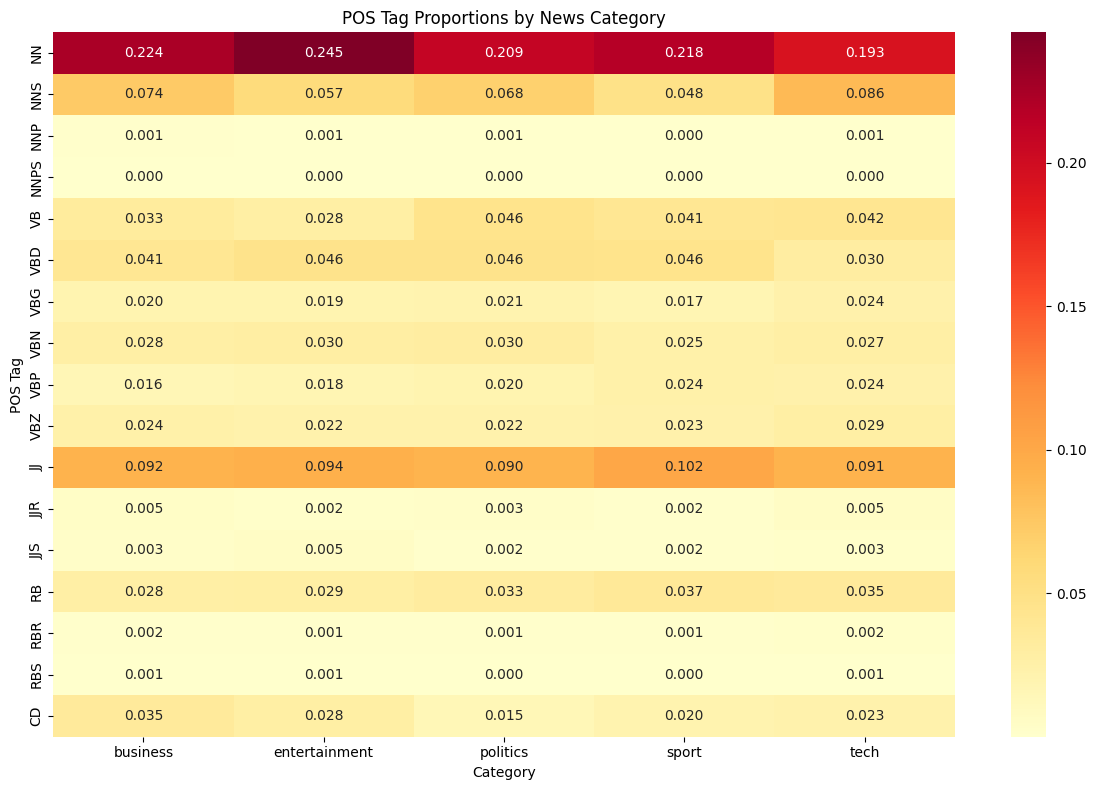


💡 ANALYSIS QUESTIONS:
1. Which category has the highest proportion of proper nouns (NNP/NNPS)?
2. Which category uses the most action verbs (VB, VBD, VBG)?
3. Are there interesting patterns in adjective (JJ) usage?
4. How does number (CD) usage vary across categories?


In [ ]:
# Analyze POS patterns by category
print("📊 POS PATTERNS BY CATEGORY")
print("=" * 50)

# Group by category and calculate mean proportions
pos_by_category = pos_df.groupby('category').mean()

# Focus on major POS categories
major_pos = ['NN', 'NNS', 'NNP', 'NNPS', 'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ',
             'JJ', 'JJR', 'JJS', 'RB', 'RBR', 'RBS', 'CD']

# Filter to only include major POS tags that exist in our data
available_pos = [pos for pos in major_pos if pos in pos_by_category.columns]

if available_pos:
    pos_summary = pos_by_category[available_pos]

    print("\n🎯 Key POS patterns by category:")
    print(pos_summary.round(4))

    # Create visualization
    plt.figure(figsize=(12, 8))
    sns.heatmap(pos_summary.T, annot=True, cmap='YlOrRd', fmt='.3f')
    plt.title('POS Tag Proportions by News Category')
    plt.xlabel('Category')
    plt.ylabel('POS Tag')
    plt.tight_layout()
    plt.show()

    # 💡 STUDENT TASK: Analyze the patterns
    # - Which categories use more nouns vs verbs?
    # - Do business articles have more numbers (CD)?
    # - Are there differences in adjective usage?

    print("\n💡 ANALYSIS QUESTIONS:")
    print("1. Which category has the highest proportion of proper nouns (NNP/NNPS)?")
    print("2. Which category uses the most action verbs (VB, VBD, VBG)?")
    print("3. Are there interesting patterns in adjective (JJ) usage?")
    print("4. How does number (CD) usage vary across categories?")
else:
    print("⚠️ No major POS tags found in the analysis. Check your POS tagging implementation.")

### POS Patterns by Category — Findings

The results show some differences in word usage across the five news categories. Entertainment has the highest proportion of singular nouns (NN), while technology has the highest proportion of plural nouns (NNS). Sports has the highest proportion of adjectives (JJ) and adverbs (RB), which may reflect the descriptive language used in sports reporting. Business has the highest proportion of numbers (CD), while politics has the lowest.

These findings show that POS patterns can help us understand differences in writing styles across news categories. However, the results do not fully confirm the original hypothesis, so further analysis would be needed to draw stronger conclusions.



### POS Analysis Questions

**1. Which category has the highest proportion of proper nouns (NNP/NNPS)?**

Sport appears to have a slightly higher proportion of proper nouns, but the differences between categories are very small. Lowercase text may also affect proper noun tagging.

**2. Which category uses the most action verbs (VB, VBD, VBG)?**

Politics, sport, and tech appear to use more action verbs. Sports articles describe actions such as winning, while political articles report events and statements.

**3. Are there interesting patterns in adjective (JJ) usage?**

Adjective usage is similar across categories, but entertainment and tech appear slightly higher. These categories often use adjectives to describe movies, products, and technology.

**4. How does number (CD) usage vary across categories?**

Business has the highest proportion of numbers, at about 0.035, while politics has the lowest, at about 0.015. Business articles often include prices, profits, and percentages, while sports articles use numbers for scores and statistics.

## 🌳 Syntax Parsing and Semantic Analysis

### 🎯 Module 5: Understanding Sentence Structure

Now we'll use spaCy to perform dependency parsing and extract semantic relationships from our news articles. This helps us understand not just what words are present, but how they relate to each other.

**Dependency Parsing Applications:**
- **Relationship Extraction:** Find connections between entities
- **Event Detection:** Identify who did what to whom
- **Information Extraction:** Extract structured facts from unstructured text

**💡 Business Value:** Understanding sentence structure helps extract more precise information about events, relationships, and actions mentioned in news articles.

### Syntactic Analysis Results

In this step, I looked at how sentences are structured in the news articles. The five examples contain between **15 and 31 sentences**, with token counts ranging from **346 to 724**. The analysis also identified noun phrases, subjects, and objects. For example, Article 4 has 31 sentences and 724 tokens, making it the longest of these five examples by token count. This analysis helps me understand how articles are organized and how words work together to express information.

In [ ]:
def extract_syntactic_features(text):
    """
    Extract syntactic features using spaCy dependency parsing

    💡 TIP: This function should extract:
    - Dependency relations
    - Subject-verb-object patterns
    - Noun phrases
    - Verb phrases
    """
    if not text or pd.isna(text):
        return {}

    # Process text with spaCy
    doc = nlp(str(text))

    features = {
        'num_sentences': len(list(doc.sents)),
        'num_tokens': len(doc),
        'dependency_relations': [],
        'noun_phrases': [],
        'verb_phrases': [],
        'subjects': [],
        'objects': []
    }

    # 🚀 YOUR CODE HERE: Extract syntactic features

    # Extract dependency relations
    for token in doc:
        if not token.is_space and not token.is_punct:
            features['dependency_relations'].append(token.dep_)

    # Extract noun phrases
    for chunk in doc.noun_chunks:
        features['noun_phrases'].append(chunk.text.lower())

    # Extract subjects and objects
    for token in doc:
        if token.dep_ in ['nsubj', 'nsubjpass']:  # Subjects
            features['subjects'].append(token.text.lower())
        elif token.dep_ in ['dobj', 'iobj', 'pobj']:  # Objects
            features['objects'].append(token.text.lower())

    # Count dependency types
    dep_counts = Counter(features['dependency_relations'])
    features['dependency_counts'] = dict(dep_counts)

    return features

# Apply syntactic analysis to sample articles
print("🌳 Performing syntactic analysis...")

# Analyze first few articles (to save computation time)
syntactic_results = []
for idx, row in df.head(5).iterrows():  # Limit to first 5 for demo
    features = extract_syntactic_features(row['full_text'])
    features['category'] = row['category']
    features['article_id'] = row['article_id']
    syntactic_results.append(features)

print("✅ Syntactic analysis complete!")

# Display results
for i, result in enumerate(syntactic_results):
    print(f"\n📰 Article {i+1} ({result['category']}):")
    print(f"  Sentences: {result['num_sentences']}")
    print(f"  Tokens: {result['num_tokens']}")
    print(f"  Noun phrases: {result['noun_phrases'][:3]}...")  # Show first 3
    print(f"  Subjects: {result['subjects'][:3]}...")  # Show first 3
    print(f"  Objects: {result['objects'][:3]}...")  # Show first 3

🌳 Performing syntactic analysis...
✅ Syntactic analysis complete!

📰 Article 1 (business):
  Sentences: 15
  Tokens: 346
  Noun phrases: ['-', 'boss', 'defence lawyers']...
  Subjects: ['-', 'boss', 'worldcom']...
  Objects: ['lawyers', 'ebbers', 'battery']...

📰 Article 2 (business):
  Sentences: 15
  Tokens: 368
  Noun phrases: ['german business confidence', 'german business confidence', 'february']...
  Subjects: ['confidence', 'ifo', 'index']...
  Objects: ['confidence', 'february', 'hopes']...

📰 Article 3 (business):
  Sentences: 24
  Tokens: 587
  Noun phrases: ['bbc poll', 'economic gloom citizens', 'a majority']...
  Subjects: ['poll', 'citizens', 'economy']...
  Objects: ['majority', 'nations', 'poll']...

📰 Article 4 (tech):
  Sentences: 31
  Tokens: 724
  Noun phrases: ['lifestyle', 'mobile choice', 'faster  better or funkier hardware']...
  Subjects: ['lifestyle', 'governs', 'firms']...
  Objects: ['choice', 'hardware', 'research']...

📰 Article 5 (business):
  Sentences: 

In [ ]:
# Visualize dependency parsing for a sample sentence
from spacy import displacy

# Choose a sample sentence
sample_sentence = df.iloc[0]['content']  # First article's content
print(f"📝 Sample sentence: {sample_sentence}")

# Process with spaCy
doc = nlp(sample_sentence)

# Display dependency tree (this works best in Jupyter)
print("\n🌳 Dependency Parse Visualization:")
try:
    # This will create an interactive visualization in Jupyter
    displacy.render(doc, style="dep", jupyter=True)
except:
    # Fallback: print dependency information
    print("\n🔗 Dependency Relations:")
    for token in doc:
        if not token.is_space and not token.is_punct:
            print(f"  {token.text} --> {token.dep_} --> {token.head.text}")

# 💡 STUDENT TASK: Extend syntactic analysis
# - Compare syntactic complexity across categories
# - Extract action patterns (who did what)
# - Identify most common dependency relations per category
# - Create features for classification based on syntax

📝 Sample sentence: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.  cynthia cooper  worldcom s ex-head of internal accounting  alerted directors to irregular accounting practices at the us telecoms giant in 2002. her warnings led to the collapse of the firm following the discovery of an $11bn (£5.7bn) accounting fraud. mr ebbers has pleaded not guilty to charges of fraud and conspiracy.  prosecution lawyers have argued that mr ebbers orchestrated a series of accounting tricks at worldcom  ordering employees to hide expenses and inflate revenues to meet wall street earnings estimates. but ms cooper  who now runs her own consulting business  told a jury in new york on wednesday that external auditors arthur andersen had approved worldcom s accounting in early 2001 and 2002. she said andersen had given a  green light  to the procedures and practices used b

### Dependency Parse Analysis

In this section, using spaCy  allow to analyze the sentence structure of a news article. The output shows each word with its part of speech and its grammatical relationship to other words. The dependency parse visualization uses arcs to connect related words, helping me see how sentences are organized. For example, labels such as `nsubj` identify a subject, while `dobj` identifies a direct object. Some words may be tagged incorrectly, so the results are useful for understanding sentence structure but are not always perfect.

## 😊 Sentiment and Emotion Analysis

### 🎯 Module 6: Understanding Emotional Tone

Let's analyze the sentiment and emotional tone of our news articles. This can reveal interesting patterns about how different types of news are presented and perceived.

**Sentiment Analysis Applications:**
- **Media Bias Detection:** Identify emotional slant in news coverage
- **Public Opinion Tracking:** Monitor sentiment trends over time
- **Content Recommendation:** Suggest articles based on emotional tone

**💡 Hypothesis:** Different news categories might have different emotional profiles - sports might be more positive, politics more negative, etc.

In [ ]:

# Initialize sentiment analyzer
sia = SentimentIntensityAnalyzer()

def analyze_sentiment(text):
    """
    Analyze sentiment using VADER.
    """
    if text is None or pd.isna(text):
        return {
            'compound': 0,
            'pos': 0,
            'neu': 1,
            'neg': 0,
            'sentiment_label': 'neutral'
        }

    scores = sia.polarity_scores(str(text))

    if scores['compound'] >= 0.05:
        scores['sentiment_label'] = 'positive'
    elif scores['compound'] <= -0.05:
        scores['sentiment_label'] = 'negative'
    else:
        scores['sentiment_label'] = 'neutral'

    return scores


# Analyze the article content
print("Analyzing sentiment...")

sentiment_results = []

for idx, row in df.iterrows():
    content_sentiment = analyze_sentiment(row['content'])

    result = {
        'article_id': row['article_id'],
        'category': row['category'],
        'content_sentiment': content_sentiment['compound'],
        'content_label': content_sentiment['sentiment_label'],
        'pos_score': content_sentiment['pos'],
        'neu_score': content_sentiment['neu'],
        'neg_score': content_sentiment['neg']
    }

    sentiment_results.append(result)

# Convert results to a DataFrame
sentiment_df = pd.DataFrame(sentiment_results)

print("Sentiment analysis complete!")
print(f"Analyzed {len(sentiment_df)} articles")

# Display sample results
print("\nSample sentiment results:")
print(
    sentiment_df[
        ['category', 'content_sentiment', 'content_label']
    ].head()
)


Analyzing sentiment...
Sentiment analysis complete!
Analyzed 1490 articles

Sample sentiment results:
   category  content_sentiment content_label
0  business            -0.9701      negative
1  business             0.7623      positive
2  business            -0.9318      negative
3      tech             0.9554      positive
4  business            -0.9486      negative


### Sentiment Analysis Results

The sentiment analysis covered **1,490 news articles** and assigned each article a score and a label. In the sample results, two business articles had negative scores of **-0.9701** and **-0.9318**, while another business article had a positive score of **0.7623**. The tech article had a positive score of **0.9554**. This shows that articles in the same category can have different emotional tones.

In [ ]:
print("Sentiment results:")
print(sentiment_df.columns.tolist())
print(sentiment_df.head())

print("\nNumber of articles:", len(sentiment_df))

Sentiment results:
['article_id', 'category', 'content_sentiment', 'content_label', 'pos_score', 'neu_score', 'neg_score']
   article_id  category  content_sentiment content_label  pos_score  \
0        1833  business            -0.9701      negative      0.063   
1         154  business             0.7623      positive      0.117   
2        1101  business            -0.9318      negative      0.083   
3        1976      tech             0.9554      positive      0.058   
4         917  business            -0.9486      negative      0.078   

   neu_score  neg_score  
0      0.793      0.144  
1      0.786      0.096  
2      0.809      0.108  
3      0.916      0.026  
4      0.807      0.115  

Number of articles: 1490


SENTIMENT ANALYSIS BY CATEGORY

Sentiment statistics by category:
              content_sentiment                         pos_score neu_score  \
                           mean     std     min     max      mean      mean   
category                                                                      
business                 0.2404  0.8370 -0.9985  0.9995    0.0926    0.8370   
entertainment            0.5991  0.6796 -0.9978  0.9999    0.1356    0.8107   
politics                 0.0578  0.8811 -0.9984  0.9999    0.0947    0.8184   
sport                    0.5541  0.7244 -0.9967  0.9996    0.1360    0.7933   
tech                     0.5233  0.7557 -0.9991  0.9993    0.0895    0.8598   

              neg_score  
                   mean  
category                 
business         0.0704  
entertainment    0.0537  
politics         0.0869  
sport            0.0707  
tech             0.0507  

Sentiment distribution (%) by category:
content_label  negative  neutral  positive
category 

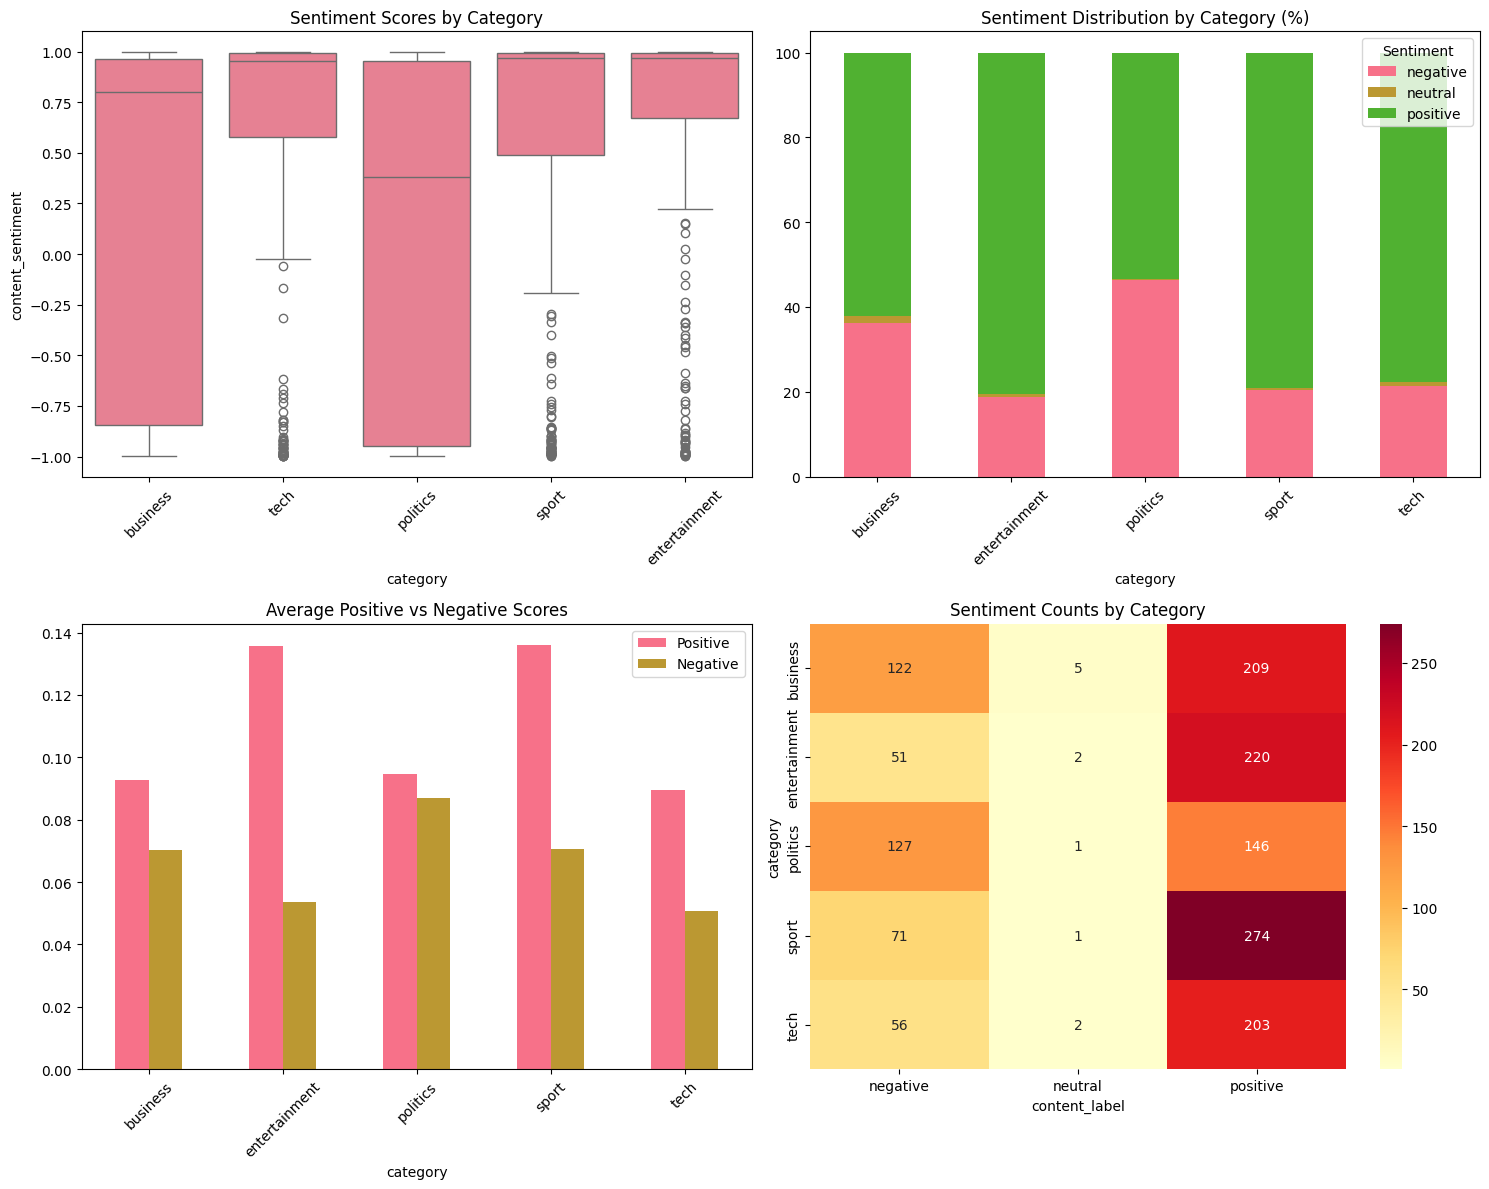

In [ ]:
# Analyze sentiment patterns by category
print("SENTIMENT ANALYSIS BY CATEGORY")
print("=" * 50)

# Calculate sentiment statistics by category
sentiment_by_category = sentiment_df.groupby('category').agg({
    'content_sentiment': ['mean', 'std', 'min', 'max'],
    'pos_score': 'mean',
    'neu_score': 'mean',
    'neg_score': 'mean'
}).round(4)

print("\nSentiment statistics by category:")
print(sentiment_by_category)

# Sentiment distribution by category
sentiment_dist = sentiment_df.groupby(
    ['category', 'content_label']
).size().unstack(fill_value=0)

sentiment_dist_pct = sentiment_dist.div(
    sentiment_dist.sum(axis=1), axis=0
) * 100

print("\nSentiment distribution (%) by category:")
print(sentiment_dist_pct.round(2))

# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Sentiment scores by category
sns.boxplot(
    data=sentiment_df,
    x='category',
    y='content_sentiment',
    ax=axes[0, 0]
)
axes[0, 0].set_title('Sentiment Scores by Category')
axes[0, 0].tick_params(axis='x', rotation=45)

# 2. Sentiment label distribution
sentiment_dist_pct.plot(
    kind='bar', ax=axes[0, 1], stacked=True
)
axes[0, 1].set_title('Sentiment Distribution by Category (%)')
axes[0, 1].tick_params(axis='x', rotation=45)
axes[0, 1].legend(title='Sentiment')

# 3. Average positive and negative scores
category_means = sentiment_df.groupby('category')[
    ['pos_score', 'neg_score']
].mean()

category_means.plot(kind='bar', ax=axes[1, 0])
axes[1, 0].set_title('Average Positive vs Negative Scores')
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].legend(['Positive', 'Negative'])

# 4. Sentiment count heatmap
sentiment_pivot = sentiment_df.pivot_table(
    values='article_id',
    index='category',
    columns='content_label',
    aggfunc='count',
    fill_value=0
)

sns.heatmap(
    sentiment_pivot,
    annot=True,
    fmt='d',
    ax=axes[1, 1],
    cmap='YlOrRd'
)
axes[1, 1].set_title('Sentiment Counts by Category')

plt.tight_layout()
plt.show()


### Sentiment Analysis by Category

The results show differences in sentiment across the five news categories. Entertainment has the highest average sentiment score (**0.5991**), followed by sports (**0.5541**) and tech (**0.5233**). Politics has the lowest average score (**0.0578**) and the highest percentage of negative articles (**46.35%**). Entertainment has the highest percentage of positive articles at **80.59%**. The charts make these differences easier to compare. Overall, the results show that the emotional tone of news articles varies depending on the category.